In [16]:
import numpy as np
np.set_printoptions(threshold=10000, suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [19]:
df = pd.read_csv("credit_scoring.csv" , sep = ";")
df.head()

,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price,Status
0,9.0,1.0,60.0,30.0,0.0,1.0,1.0,73.0,129.0,0.0,0.0,800.0,846.0,1
1,17.0,1.0,60.0,58.0,1.0,1.0,0.0,48.0,131.0,0.0,0.0,1000.0,1658.0,1
2,10.0,0.0,36.0,46.0,0.0,2.0,1.0,90.0,200.0,3000.0,0.0,2000.0,2985.0,0
3,0.0,1.0,60.0,24.0,1.0,1.0,0.0,63.0,182.0,2500.0,0.0,900.0,1325.0,1
4,0.0,1.0,36.0,26.0,1.0,1.0,0.0,46.0,107.0,0.0,0.0,310.0,910.0,1


In [20]:
X = df.drop("Status", axis = 1).values
y = df["Status"].values
print ("Type de X : ", type(X))
print ("Type de y : ", type(y))


Type de X :  <class 'numpy.ndarray'>
Type de y :  <class 'numpy.ndarray'>


In [21]:
print ("Taille de X : ", X.shape)
print ("Taille de y : ", y.shape)

positifs = sum (y == 1)
negatifs = sum (y == 0)

print ("\nNombres de personnes ayant fait un crédit (y = 1) : ", positifs)
print ("Nombres de personnes n'ayant pas fait un crédit (y = 0) :", negatifs)

print ("\npourcentage positifs : ", round(positifs / len(y) * 100,2), "%")
print ("pourcentage negatifs : ", round(negatifs / len(y) * 100,2), "%")


Taille de X :  (4375, 13)
Taille de y :  (4375,)

Nombres de personnes ayant fait un crédit (y = 1) :  3159
Nombres de personnes n'ayant pas fait un crédit (y = 0) : 1216

pourcentage positifs :  72.21 %
pourcentage negatifs :  27.79 %


In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=1,
    stratify=y
)

print("Taille X_train :", X_train.shape)
print("Taille X_test  :", X_test.shape)
print("Taille y_train :", y_train.shape)
print("Taille y_test  :", y_test.shape)

import numpy as np

def proportions(label_array): 
    uniques, counts = np.unique(label_array, return_counts=True)
    total = len(label_array)
    return {int(u): round(c/total*100,2) for u, c in zip(uniques, counts)}

print("\nProportions dans y (global) :", proportions(y))
print("Proportions dans y_train     :", proportions(y_train))
print("Proportions dans y_test      :", proportions(y_test))  





Taille X_train : (2187, 13)
Taille X_test  : (2188, 13)
Taille y_train : (2187,)
Taille y_test  : (2188,)

Proportions dans y (global) : {0: np.float64(27.79), 1: np.float64(72.21)}
Proportions dans y_train     : {0: np.float64(27.8), 1: np.float64(72.2)}
Proportions dans y_test      : {0: np.float64(27.79), 1: np.float64(72.21)}


In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Dictionnaire des modèles supervisés
clé = {
    "CART": DecisionTreeClassifier(random_state=1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "MLP": MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
}

clé


{'CART': DecisionTreeClassifier(random_state=1),
 'KNN': KNeighborsClassifier(),
 'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), max_iter=500, random_state=1)}


Entraînement du modèle : CART

Matrice de confusion pour CART :

[[ 297  311]
 [ 319 1261]]


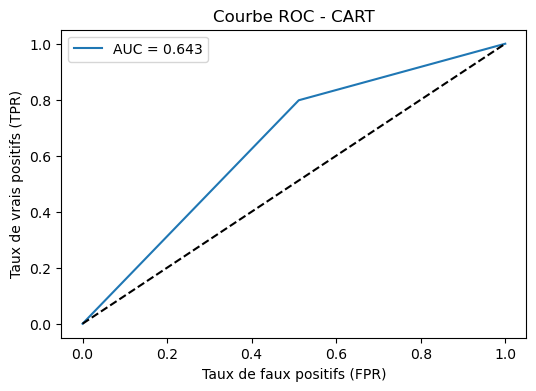

Accuracy  : 0.712
Précision : 0.802
Rappel    : 0.798
Score final = 0.757

Entraînement du modèle : KNN

Matrice de confusion pour KNN :

[[ 180  428]
 [ 221 1359]]


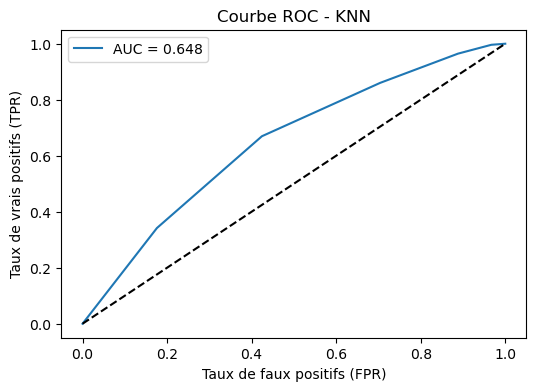

Accuracy  : 0.703
Précision : 0.760
Rappel    : 0.860
Score final = 0.782

Entraînement du modèle : MLP

Matrice de confusion pour MLP :

[[  59  549]
 [  55 1525]]


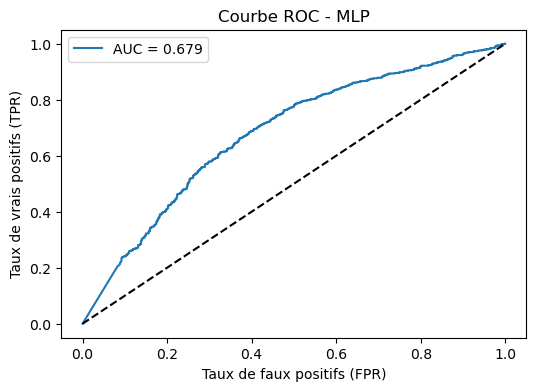

Accuracy  : 0.724
Précision : 0.735
Rappel    : 0.965
Score final = 0.845

##################################################
Meilleur modèle : MLP avec un score de 0.845
##################################################

Scores obtenus :
{'CART': 0.757114331700555, 'KNN': 0.7817543331867725, 'MLP': 0.8445693425589522}

Meilleur modèle entraîné : MLPClassifier(hidden_layer_sizes=(40, 20), max_iter=500, random_state=1)


In [25]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

def evaluation (model , X_test, y_test, model_name = "") : 
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]   
    cm = confusion_matrix(y_test, y_pred)

    print(f"\nMatrice de confusion pour {model_name} :\n")
    print(cm)

    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)

    plt.figure(figsize=(6,4))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0,1], [0,1], 'k--')   # Diagonale du hasard
    plt.xlabel("Taux de faux positifs (FPR)")
    plt.ylabel("Taux de vrais positifs (TPR)")
    plt.title(f"Courbe ROC - {model_name}")
    plt.legend()
    plt.show()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)

    print(f"Accuracy  : {accuracy:.3f}")
    print(f"Précision : {precision:.3f}")
    print(f"Rappel    : {recall:.3f}")

    best = max(precision, recall)
    score_final = (accuracy + best) / 2
    print(f"Score final = {score_final:.3f}")

    return score_final


def run_classifiers_train_test(clé, X_train, X_test, y_train, y_test):
    scores = {}  

    for name, model in clé.items():
        print("\n" + "="*50)
        print(f"Entraînement du modèle : {name}")
        print("="*50)

        
        model.fit(X_train, y_train)

       
        score = evaluation(model, X_test, y_test, model_name=name)

       
        scores[name] = score

    best_name = max(scores, key=scores.get)   
    best_model = clé[best_name]

    print("\n" + "#"*50)
    print(f"Meilleur modèle : {best_name} avec un score de {scores[best_name]:.3f}")
    print("#"*50)

    return best_model, scores


best_model, scores = run_classifiers_train_test(clé, X_train, X_test, y_train, y_test)

print("\nScores obtenus :")
print(scores)
print("\nMeilleur modèle entraîné :", best_model)

